# Atelier AI — Fashion Recommendation Analysis

This notebook documents the development and evaluation of a fashion
recommendation system for client advisors.

The task is to recommend 12 distinct products per customer based on
purchase likelihood over the following seven days, using information
available before the prediction cutoff.

The current version establishes the notebook execution environment.
Data exploration and modelling will be added incrementally.

## 1. Environment

The notebook uses the project's Python environment and imports the
`atelier_ai` package installed from the repository's `src` directory.

Dependencies are declared in `pyproject.toml` and resolved in `uv.lock`.

In [1]:
import sys
from pathlib import Path

import pandas as pd

import atelier_ai

print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Package location:", Path(atelier_ai.__file__).resolve())
print("pandas version:", pd.__version__)

Python version: 3.12.14
Python executable: /Users/oumar/Developer/portfolio/atelier-ai-project/.venv/bin/python
Package location: /Users/oumar/Developer/portfolio/atelier-ai-project/src/atelier_ai/__init__.py
pandas version: 3.0.6


## 2. Data Source and Scope

The project uses the H&M Personalized Fashion Recommendations dataset.

The initial scope includes purchase transactions, article metadata and
customer metadata. Images are deferred.

Source documentation and handling decisions are recorded in the
[data card](../docs/data_card.md). Acquired files are identified in the
[data manifest](../docs/data_manifest.json).

## 3. Data Loading

### 3.1. File Locations and Preview Parameters

The initial loading check reads the first 1,000 records from each file.
These previews are not random samples and will not be used to infer
population-level patterns.

File locations are resolved from the project's editable package.

In [2]:
PROJECT_ROOT = Path(atelier_ai.__file__).resolve().parents[2]
RAW_DATA_DIRECTORY = PROJECT_ROOT / "data" / "raw" / "hm"

PREVIEW_ROWS = 1_000

SOURCE_FILENAMES = (
    "articles.csv",
    "customers.csv",
    "transactions_train.csv",
)

for filename in SOURCE_FILENAMES:
    path = RAW_DATA_DIRECTORY / filename
    if not path.is_file():
        raise FileNotFoundError(f"Required source file not found: {path}")

print("Raw data directory found.")

Raw data directory found.


### 3.2. Limited Reads

All fields are initially read as strings to preserve their lexical
representation, including identifiers with leading zeros.

Automatic missing-value recognition is disabled for this inspection.
Empty fields therefore remain empty strings. Numerical, categorical and
date conversions will be defined after inspection.

In [3]:
previews = {}

for filename in SOURCE_FILENAMES:
    dataset_name = Path(filename).stem

    previews[dataset_name] = pd.read_csv(
        RAW_DATA_DIRECTORY / filename,
        nrows=PREVIEW_ROWS,
        dtype="string",
        keep_default_na=False,
        encoding="utf-8",
    )

### 3.3. Loading Summary

The summary reports loaded dimensions and estimated DataFrame memory
usage for each preview. Loaded row counts are not full-file row counts.

Published outputs contain structural diagnostics rather than source
records.

In [4]:
summary_rows = []

for dataset_name, frame in previews.items():
    summary_rows.append(
        {
            "dataset": dataset_name,
            "rows_loaded": len(frame),
            "columns_loaded": frame.shape[1],
            "memory_mib": (
                frame.memory_usage(index=True, deep=True).sum() / 1024**2
            ),
        }
    )

loading_summary = pd.DataFrame(summary_rows)
loading_summary.round({"memory_mib": 3})

,dataset,rows_loaded,columns_loaded,memory_mib
0,articles,1000,25,1.440
1,customers,1000,7,0.464
2,transactions_train,1000,5,0.334


### 3.4. Full-File Reading Strategy

All three files are scanned in chunks of up to 100,000 records.
Chunks are processed sequentially rather than accumulated.

Article and customer fields remain strings pending detailed inspection.

For transactions:
- customer, article and sales-channel identifiers remain strings;
- dates are parsed using the YYYY-MM-DD format;
- prices are converted to nullable Float64 values;
- blank dates and prices are treated as missing;
- invalid non-blank values raise conversion errors.

Source files are not modified. No price rescaling or currency
interpretation is applied.

In [5]:
from time import perf_counter

CHUNK_ROWS = 100_000

### 3.5. Full-File Scan

The scan reports parsed record counts, chunk counts, elapsed time and
the largest observed processed-chunk memory estimate.

Chunk memory is measured after the selected conversions. It is not a
measurement of total process memory or peak memory during parsing.

In [6]:
scan_rows = []
transaction_type_summary = None

for filename in SOURCE_FILENAMES:
    dataset_name = Path(filename).stem
    rows_read = 0
    chunks_read = 0
    max_chunk_mib = 0.0
    started_at = perf_counter()

    print(f"Scanning {filename}...", flush=True)

    with pd.read_csv(
        RAW_DATA_DIRECTORY / filename,
        chunksize=CHUNK_ROWS,
        dtype="string",
        keep_default_na=False,
        encoding="utf-8",
    ) as reader:
        for chunk in reader:
            if dataset_name == "transactions_train":
                chunk["t_dat"] = pd.to_datetime(
                    chunk["t_dat"].replace("", pd.NA),
                    format="%Y-%m-%d",
                    errors="raise",
                )

                chunk["price"] = pd.to_numeric(
                    chunk["price"].replace("", pd.NA),
                    errors="raise",
                ).astype("Float64")

            rows_read += len(chunk)
            chunks_read += 1

            chunk_mib = (
                chunk.memory_usage(index=True, deep=True).sum()
                / 1024**2
            )
            max_chunk_mib = max(max_chunk_mib, chunk_mib)

            if dataset_name == "transactions_train" and chunks_read == 1:
                transaction_type_summary = pd.DataFrame(
                    {
                        "column": chunk.columns,
                        "dtype": [
                            str(dtype) for dtype in chunk.dtypes
                        ],
                    }
                )

            if chunks_read % 50 == 0:
                print(
                    f"  {rows_read:,} records processed",
                    flush=True,
                )

            del chunk

    scan_rows.append(
        {
            "dataset": dataset_name,
            "rows_read": rows_read,
            "chunks_read": chunks_read,
            "max_chunk_mib": max_chunk_mib,
            "elapsed_seconds": perf_counter() - started_at,
        }
    )

    print(f"Completed: {rows_read:,} records.", flush=True)

scan_summary = pd.DataFrame(scan_rows)

Scanning articles.csv...
Completed: 105,542 records.
Scanning customers.csv...
Completed: 1,371,980 records.
Scanning transactions_train.csv...
  5,000,000 records processed
  10,000,000 records processed
  15,000,000 records processed
  20,000,000 records processed
  25,000,000 records processed
  30,000,000 records processed
Completed: 31,788,324 records.


In [7]:
scan_summary.round(
    {
        "max_chunk_mib": 2,
        "elapsed_seconds": 2,
    }
)

,dataset,rows_read,chunks_read,max_chunk_mib,elapsed_seconds
0,articles,105542,2,147.52,0.63
1,customers,1371980,14,46.44,3.22
2,transactions_train,31788324,318,22.79,44.17


### 3.6. Transaction Types

The table records the transaction column types after conversion in
the first processed chunk. The same conversion rules are applied
throughout the scan.

In [8]:
transaction_type_summary

,column,dtype
0,t_dat,datetime64[us]
1,customer_id,string
2,article_id,string
3,price,Float64
4,sales_channel_id,string


## 4. Dataset Structure

### 4.1. Table Grain

The intended interpretation of each table is:

| Table | Expected grain | Candidate entity key |
|---|---|---|
| customers | One record per customer | customer_id |
| articles | One record per article | article_id |
| transactions_train | One recorded purchase of an article by a customer on a date | No event identifier supplied |

Entity-key uniqueness will be checked on the complete tables.

The transaction schema does not provide an order or basket identifier.
Repeated customer–article–date combinations must not automatically be
treated as ingestion errors.

### 4.2. Article and Product Identifiers

Recommendations and transaction relevance are defined at the
`article_id` level.

The preview is used to examine whether `product_code` and `article_id`
have the same granularity. This diagnostic covers only the first
1,000 article records and does not establish full-table key uniqueness.

In [9]:
identifier_rows = []

articles_preview = previews["articles"]

for column in ("article_id", "product_code"):
    values = articles_preview[column]

    identifier_rows.append(
        {
            "column": column,
            "rows_examined": len(values),
            "distinct_nonempty_values": values[values.ne("")].nunique(),
            "empty_values": int(values.eq("").sum()),
        }
    )

article_identifier_summary = pd.DataFrame(identifier_rows)
article_identifier_summary

,column,rows_examined,distinct_nonempty_values,empty_values
0,article_id,1000,1000,0
1,product_code,1000,268,0


The preview contains 1,000 distinct article identifiers and 268 distinct
product codes, with no empty values in either inspected column.

Multiple article identifiers therefore share a product code in this
preview. The two identifiers must not be used interchangeably.

Full-table uniqueness and article-to-product consistency remain to be
validated.

### 4.3. Expected Relationships

Transactions reference customers through `customer_id` and articles
through `article_id`.

The intended joins from transactions to customer and article metadata
are many-to-one: multiple purchase records can reference one entity
record.

These relationships are expectations to validate. Duplicate entity
keys could multiply transaction rows during joins; unmatched references
could leave metadata unavailable.

Key uniqueness, reference coverage and join cardinality will be checked
during data-quality validation.

### 4.4. Field Semantics and Interpretation Limits

The [data dictionary](../docs/data_dictionary.md) documents all source
columns, their working meanings, logical roles and handling decisions.

Reading types are distinguished from semantic roles: numeric-looking
codes can represent categories, while string fields can contain values
that will later be interpreted as numerical or temporal measurements.

Unresolved definitions include FN and Active, price units and scaling,
and sales-channel labels. These fields are not assigned unsupported
business meanings.

Metadata availability at historical prediction dates remains a separate
requirement from successful file loading.

Full-table key, reference and classification-consistency checks follow
during data-quality validation.

## 5. Data Quality

### 5.1. Entity-Key Completeness and Uniqueness

The complete article and customer key columns are inspected.

Checks cover:
- missing identifiers, including empty or whitespace-only fields;
- exact duplicate identifiers among nonmissing values;
- leading or trailing whitespace.

Keys are preserved as supplied. Trimming is used for diagnostics only.

Duplicate counts include every row belonging to a repeated-key group.
Checks can overlap; affected percentages use the total examined row
count as their denominator.

In [10]:
ENTITY_KEY_COLUMNS = {
    "articles": "article_id",
    "customers": "customer_id",
}

entity_key_frames = {}

for dataset_name, key_column in ENTITY_KEY_COLUMNS.items():
    entity_key_frames[dataset_name] = pd.read_csv(
        RAW_DATA_DIRECTORY / f"{dataset_name}.csv",
        usecols=[key_column],
        dtype="string",
        keep_default_na=False,
        encoding="utf-8",
    )

In [11]:
key_profile_rows = []
key_check_rows = []

for dataset_name, key_column in ENTITY_KEY_COLUMNS.items():
    frame = entity_key_frames[dataset_name]
    values = frame[key_column]
    total_rows = len(values)

    if total_rows == 0:
        raise ValueError(f"Entity table is empty: {dataset_name}")

    stripped_values = values.str.strip()

    missing_mask = stripped_values.fillna("").eq("")
    nonmissing_values = values[~missing_mask]

    affected_counts = {
        "missing_keys": int(missing_mask.sum()),
        "duplicate_key_rows": int(
            nonmissing_values.duplicated(keep=False).sum()
        ),
        "surrounding_whitespace": int(
            values.ne(stripped_values).fillna(False).sum()
        ),
    }

    key_profile_rows.append(
        {
            "dataset": dataset_name,
            "key_column": key_column,
            "rows": total_rows,
            "distinct_nonmissing_keys": int(
                nonmissing_values.nunique()
            ),
            "memory_mib": (
                frame.memory_usage(index=True, deep=True).sum()
                / 1024**2
            ),
        }
    )

    for check_name, affected_rows in affected_counts.items():
        key_check_rows.append(
            {
                "dataset": dataset_name,
                "check": check_name,
                "affected_rows": affected_rows,
                "affected_pct": 100 * affected_rows / total_rows,
                "passed": affected_rows == 0,
            }
        )

key_profile = pd.DataFrame(key_profile_rows)
key_checks = pd.DataFrame(key_check_rows)

### 5.2. Entity-Key Check Results

The profile reports full-column dimensions and distinct nonmissing keys.
The check table reports affected counts, percentages and outcomes.

Passing these checks establishes completeness and exact uniqueness of
the inspected entity keys, with no surrounding whitespace detected.
It does not establish transaction reference coverage or overall
dataset quality.

In [12]:
key_profile.round({"memory_mib": 2})

,dataset,key_column,rows,distinct_nonmissing_keys,memory_mib
0,articles,article_id,105542,105542,5.94
1,customers,customer_id,1371980,1371980,147.85


In [13]:
key_checks.round({"affected_pct": 4})

,dataset,check,affected_rows,affected_pct,passed
0,articles,missing_keys,0,0.0,True
1,articles,duplicate_key_rows,0,0.0,True
2,articles,surrounding_whitespace,0,0.0,True
3,customers,missing_keys,0,0.0,True
4,customers,duplicate_key_rows,0,0.0,True
5,customers,surrounding_whitespace,0,0.0,True


### 5.3. Transaction Reference Validation

Transaction customer and article references are checked against the
complete entity-key columns validated previously.

Each reference is classified as:
- missing: null, empty or whitespace-only;
- unknown: nonmissing but absent from its reference table;
- matched: present in its reference table.

Counts describe transaction rows, not distinct identifiers.
Matching uses exact source values without automatic normalization.

Only the two reference columns are read, in chunks.

In [14]:
if not key_checks["passed"].all():
    raise ValueError(
        "Resolve entity-key check failures before validating references."
    )

reference_indexes = {}

for dataset_name, key_column in ENTITY_KEY_COLUMNS.items():
    reference_indexes[key_column] = pd.Index(
        entity_key_frames[dataset_name][key_column]
    )

In [15]:
reference_counts = {}

for key_column in reference_indexes:
    reference_counts[key_column] = {
        "missing_rows": 0,
        "unknown_rows": 0,
        "matched_rows": 0,
    }

transaction_rows_checked = 0

with pd.read_csv(
    RAW_DATA_DIRECTORY / "transactions_train.csv",
    usecols=list(reference_indexes),
    chunksize=CHUNK_ROWS,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8",
) as reader:
    for chunk_number, chunk in enumerate(reader, start=1):
        transaction_rows_checked += len(chunk)

        for key_column, reference_index in reference_indexes.items():
            values = chunk[key_column]

            missing_mask = values.fillna("").str.strip().eq("")
            positions = reference_index.get_indexer(values)

            matched_mask = (~missing_mask) & (positions >= 0)
            unknown_mask = (~missing_mask) & (positions < 0)

            counts = reference_counts[key_column]
            counts["missing_rows"] += int(missing_mask.sum())
            counts["unknown_rows"] += int(unknown_mask.sum())
            counts["matched_rows"] += int(matched_mask.sum())

        if chunk_number % 50 == 0:
            print(
                f"{transaction_rows_checked:,} transaction rows checked",
                flush=True,
            )

        del chunk

if transaction_rows_checked == 0:
    raise ValueError("No transaction records were read.")

print(f"Completed: {transaction_rows_checked:,} transaction rows checked.")

5,000,000 transaction rows checked
10,000,000 transaction rows checked
15,000,000 transaction rows checked
20,000,000 transaction rows checked
25,000,000 transaction rows checked
30,000,000 transaction rows checked
Completed: 31,788,324 transaction rows checked.


### 5.4. Reference Coverage Results

Reference coverage is the proportion of all examined transaction rows
whose reference matches the corresponding entity table.

Missing and unknown references are reported separately.
A reference passes when both counts are zero.

Issues across customer and article references can overlap within the
same transaction row.

In [16]:
reference_summary_rows = []

for key_column, counts in reference_counts.items():
    reference_summary_rows.append(
        {
            "key_column": key_column,
            "rows_examined": transaction_rows_checked,
            "missing_rows": counts["missing_rows"],
            "unknown_rows": counts["unknown_rows"],
            "matched_rows": counts["matched_rows"],
            "matched_pct": (
                100 * counts["matched_rows"] / transaction_rows_checked
            ),
            "passed": (
                counts["missing_rows"] == 0
                and counts["unknown_rows"] == 0
            ),
        }
    )

reference_summary = pd.DataFrame(reference_summary_rows)
reference_summary.round({"matched_pct": 4})

,key_column,rows_examined,missing_rows,unknown_rows,matched_rows,matched_pct,passed
0,article_id,31788324,0,0,31788324,100.0,True
1,customer_id,31788324,0,0,31788324,100.0,True


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

### 5.5. Completeness Profiling Policy

All source columns are inspected across the complete files.

Missing values are defined as null, empty or whitespace-only fields.
Reading uses keep_default_na=False, so nonempty textual placeholders
such as Unknown, NONE or NaN are preserved for separate interpretation.

The resulting percentages describe missingness under this explicit
policy. They do not establish the meaning of placeholder categories.

Files are processed in chunks. No records are dropped, imputed or
written back to the source files.

In [22]:
completeness_rows = []

for filename in SOURCE_FILENAMES:
    dataset_name = Path(filename).stem
    rows_scanned = 0
    missing_counts = {}

    print(f"Profiling completeness: {filename}", flush=True)

    with pd.read_csv(
        RAW_DATA_DIRECTORY / filename,
        chunksize=CHUNK_ROWS,
        dtype="string",
        keep_default_na=False,
        encoding="utf-8",
    ) as reader:
        for chunk_number, chunk in enumerate(reader, start=1):
            rows_scanned += len(chunk)

            for column in chunk.columns:
                values = chunk[column]
                missing_mask = values.fillna("").str.strip().eq("")

                missing_counts[column] = (
                    missing_counts.get(column, 0)
                    + int(missing_mask.sum())
                )

            if chunk_number % 50 == 0:
                print(
                    f"  {rows_scanned:,} records inspected",
                    flush=True,
                )

            del chunk

    if rows_scanned == 0:
        raise ValueError(f"Source table is empty: {dataset_name}")

    for column, missing_rows in missing_counts.items():
        completeness_rows.append(
            {
                "dataset": dataset_name,
                "column": column,
                "rows_examined": rows_scanned,
                "missing_rows": missing_rows,
                "missing_pct": 100 * missing_rows / rows_scanned,
            }
        )

    print(f"Completed: {rows_scanned:,} records.", flush=True)

completeness_summary = (
    pd.DataFrame(completeness_rows)
    .sort_values(
        ["dataset", "missing_pct", "column"],
        ascending=[True, False, True],
    )
    .reset_index(drop=True)
)

Profiling completeness: articles.csv
Completed: 105,542 records.
Profiling completeness: customers.csv
Completed: 1,371,980 records.
Profiling completeness: transactions_train.csv
  5,000,000 records inspected
  10,000,000 records inspected
  15,000,000 records inspected
  20,000,000 records inspected
  25,000,000 records inspected
  30,000,000 records inspected
Completed: 31,788,324 records.


### 5.6. Completeness Results

The table reports one result per source column, including columns with
no missing values detected.

Percentages use the complete row count of the corresponding source
file. No automatic feature-exclusion threshold is applied.

In [23]:
completeness_summary.round({"missing_pct": 3})

,dataset,column,rows_examined,missing_rows,missing_pct
0,articles,detail_desc,105542,416,0.394
1,articles,article_id,105542,0,0.000
2,articles,colour_group_code,105542,0,0.000
3,articles,colour_group_name,105542,0,0.000
4,articles,department_name,105542,0,0.000
5,articles,department_no,105542,0,0.000
6,articles,garment_group_name,105542,0,0.000
7,articles,garment_group_no,105542,0,0.000
8,articles,graphical_appearance_name,105542,0,0.000
9,articles,graphical_appearance_no,105542,0,0.000


### 5.7. Missingness by Field

The chart displays fields with nonzero missingness, ordered by rate.
Zero-missingness fields remain available in the complete results table.

Labels identify the source table and column. Rates cover the complete
source files under the null-or-blank policy defined above.

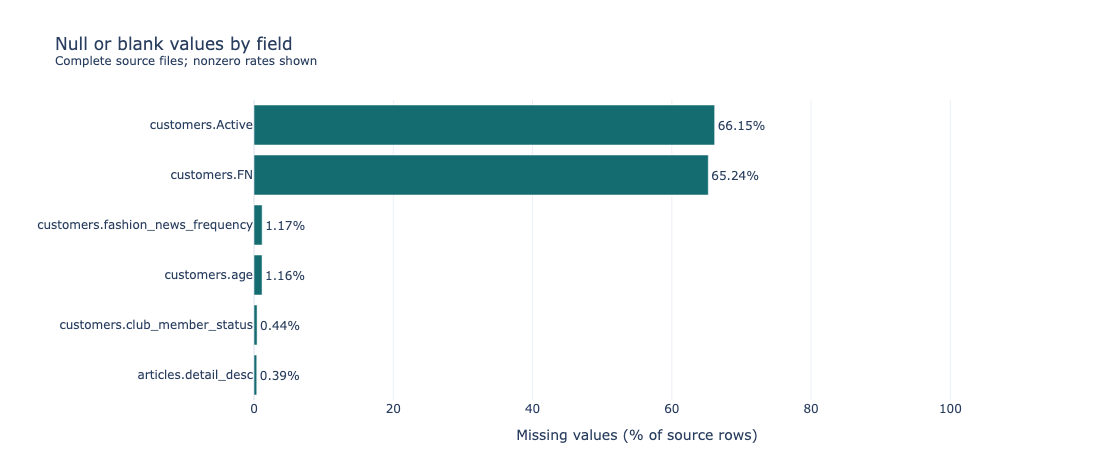

In [24]:
plot_data = (
    completeness_summary.loc[
        completeness_summary["missing_rows"].gt(0)
    ]
    .sort_values(
        ["missing_pct", "dataset", "column"],
        ascending=[False, True, True],
    )
    .copy()
)

plot_data["field"] = (
    plot_data["dataset"] + "." + plot_data["column"]
)

if plot_data.empty:
    print("No null or blank values detected under the current policy.")

else:
    fig = px.bar(
        plot_data,
        x="missing_pct",
        y="field",
        orientation="h",
        text="missing_pct",
        custom_data=["missing_rows", "rows_examined"],
        color_discrete_sequence=["#146C70"],
        template="plotly_white",
        labels={
            "missing_pct": "Missing values (% of source rows)",
            "field": "",
        },
        title=(
            "Null or blank values by field"
            "<br><sup>Complete source files; nonzero rates shown</sup>"
        ),
    )

    fig.update_traces(
        texttemplate="%{x:.2f}%",
        textposition="outside",
        cliponaxis=False,
        hovertemplate=(
            "<b>%{y}</b><br>"
            "Missing rows: %{customdata[0]:,.0f}<br>"
            "Rows examined: %{customdata[1]:,.0f}<br>"
            "Missing rate: %{x:.3f}%"
            "<extra></extra>"
        ),
    )

    fig.update_xaxes(
        range=[0, 110],
        tickvals=list(range(0, 101, 20)),
        ticksuffix="%",
    )

    fig.update_yaxes(
        categoryorder="array",
        categoryarray=plot_data["field"].tolist(),
        autorange="reversed",
        automargin=True,
    )

    fig.update_layout(
        width=1100,
        height=max(420, 50 * len(plot_data) + 170),
        margin=dict(l=40, r=80, t=100, b=70),
        showlegend=False,
    )

    fig.show(
        renderer="plotly_mimetype+png",
        config={"displaylogo": False},
    )

In [25]:
from collections import Counter

### 5.8. Customer Category Profiling Policy

Four customer attributes are profiled across the complete customer file:
FN, Active, club_member_status and fashion_news_frequency.

Counts preserve exact source values, including case and whitespace.
Each percentage uses the complete customer row count as its denominator.

Null, empty and whitespace-only values follow the existing missingness
policy. Selected nonempty textual values are flagged as potential
placeholder categories for semantic review.

A placeholder flag is a diagnostic signal, not an invalidity decision.
No categories are merged, replaced or assigned a business meaning.

In [26]:
CUSTOMER_CATEGORY_COLUMNS = (
    "FN",
    "Active",
    "club_member_status",
    "fashion_news_frequency",
)

PLACEHOLDER_CANDIDATES = frozenset({
    "unknown",
    "none",
    "nan",
    "n/a",
    "na",
    "null",
    "not available",
    "not specified",
})

In [27]:
category_counts = {
    column: Counter()
    for column in CUSTOMER_CATEGORY_COLUMNS
}

customer_rows_profiled = 0

with pd.read_csv(
    RAW_DATA_DIRECTORY / "customers.csv",
    usecols=list(CUSTOMER_CATEGORY_COLUMNS),
    chunksize=CHUNK_ROWS,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8",
) as reader:
    for chunk in reader:
        customer_rows_profiled += len(chunk)

        for column in CUSTOMER_CATEGORY_COLUMNS:
            chunk_counts = (
                chunk[column]
                .value_counts(dropna=False)
                .to_dict()
            )

            category_counts[column].update(chunk_counts)

        del chunk

if customer_rows_profiled == 0:
    raise ValueError("No customer records were inspected.")

for column, counts in category_counts.items():
    if sum(counts.values()) != customer_rows_profiled:
        raise ValueError(
            f"Category counts do not reconcile for {column}."
        )

print(f"Customer records profiled: {customer_rows_profiled:,}")

Customer records profiled: 1,371,980


In [28]:
category_profile_rows = []

for column, counts in category_counts.items():
    for raw_value, rows in counts.items():
        is_missing = (
            pd.isna(raw_value)
            or raw_value.strip() == ""
        )

        is_placeholder_candidate = (
            not is_missing
            and raw_value.strip().casefold()
            in PLACEHOLDER_CANDIDATES
        )

        category_profile_rows.append({
            "column": column,
            "raw_value": raw_value,
            "value_display": repr(raw_value),
            "rows": rows,
            "pct_rows": 100 * rows / customer_rows_profiled,
            "is_missing": is_missing,
            "placeholder_candidate": is_placeholder_candidate,
        })

category_profile = (
    pd.DataFrame(category_profile_rows)
    .sort_values(
        ["column", "rows", "value_display"],
        ascending=[True, False, True],
    )
    .reset_index(drop=True)
)

### 5.9. Customer Category Frequencies

The table reports exact source categories and their frequencies.

Quoted values make empty strings and surrounding whitespace visible.
Missingness and potential textual placeholders are reported separately.

Displayed percentages are rounded. Row counts remain available to
identify rare categories whose rounded percentage approaches zero.

In [29]:
category_profile.drop(
    columns="raw_value"
).round({
    "pct_rows": 3,
})

,column,value_display,rows,pct_rows,is_missing,placeholder_candidate
0,Active,'',907576,66.151,True,False
1,Active,'1.0',464404,33.849,False,False
2,FN,'',895050,65.238,True,False
3,FN,'1.0',476930,34.762,False,False
4,club_member_status,'ACTIVE',1272491,92.749,False,False
5,club_member_status,'PRE-CREATE',92960,6.776,False,False
6,club_member_status,'',6062,0.442,True,False
7,club_member_status,'LEFT CLUB',467,0.034,False,False
8,fashion_news_frequency,'NONE',877711,63.974,False,True
9,fashion_news_frequency,'Regularly',477416,34.798,False,False
